# Chapter 5: Targeting: who should get which email?

The results settled that both emails work and the men's email is the better one on average. The remaining question from the [project brief](../docs/1_project_brief.md) is: *who should get each one?*

The [analysis plan](../docs/2_analysis_plan.md) classed this as **exploratory**: segment results not planned in advance cannot be confirmed by this test. The approach:

1. **The slicing trap:** why a table of segment results is mostly noise.
2. **A hypothesis with a reason:** does the email work better when its merchandise matches what the customer buys?
3. **Uplift models:** can machine learning find responsive customers? Evaluated honestly on held-out data.
4. **Targeting policies:** which way of assigning emails would make the most money?

Summary: [targeting](../docs/5_targeting.md).

In [1]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from expt.data import load_hillstrom
from expt.inference import compare_means, compare_proportions, holm
from expt.plotting import ARM_COLORS, ARM_LABELS, BAND, INK, INK_2, SERIES, new_figure, style_axes
from expt.policy import compare_policies
from expt.uplift import qini_coefficient, qini_curve, s_learner, t_learner

df = load_hillstrom()
df["bought"] = np.select(
    [(df["mens"] == 1) & (df["womens"] == 0), (df["mens"] == 0) & (df["womens"] == 1)],
    ["men's only", "women's only"], "both",
)
arm = df["arm"].astype(str).to_numpy()
GROSS_MARGIN, COST_PER_EMAIL = 0.40, 0.0225

## 1. The slicing trap

The natural first move is to cut the results by every customer attribute and look for groups where an email works especially well or badly. Here is the revenue lift of each email in 18 segments:

In [2]:
SEGMENTS = ["bought", "channel", "newbie", "zip_code", "history_segment"]
rows = []
for var in SEGMENTS:
    for level, g in df.groupby(var, observed=True):
        ctrl = g.loc[g["arm"] == "control", "spend"]
        for email in ["mens", "womens"]:
            r = compare_means(g.loc[g["arm"] == email, "spend"], ctrl)
            rows.append({"segment": f"{var} = {level}", "email": email, "customers": len(g),
                         "lift": r.diff, "low": r.diff_low, "high": r.diff_high, "p_value": r.p_value})
seg = pd.DataFrame(rows)
seg["p_holm"] = holm(seg["p_value"])
print(f"{len(seg)} segment comparisons")
print(f"Raw p < 0.05: {(seg['p_value'] < 0.05).sum()}   |   Holm-adjusted p < 0.05: {(seg['p_holm'] < 0.05).sum()}")
print(f"Negative point estimates: {(seg['lift'] < 0).sum()}")

36 segment comparisons
Raw p < 0.05: 24   |   Holm-adjusted p < 0.05: 7
Negative point estimates: 2


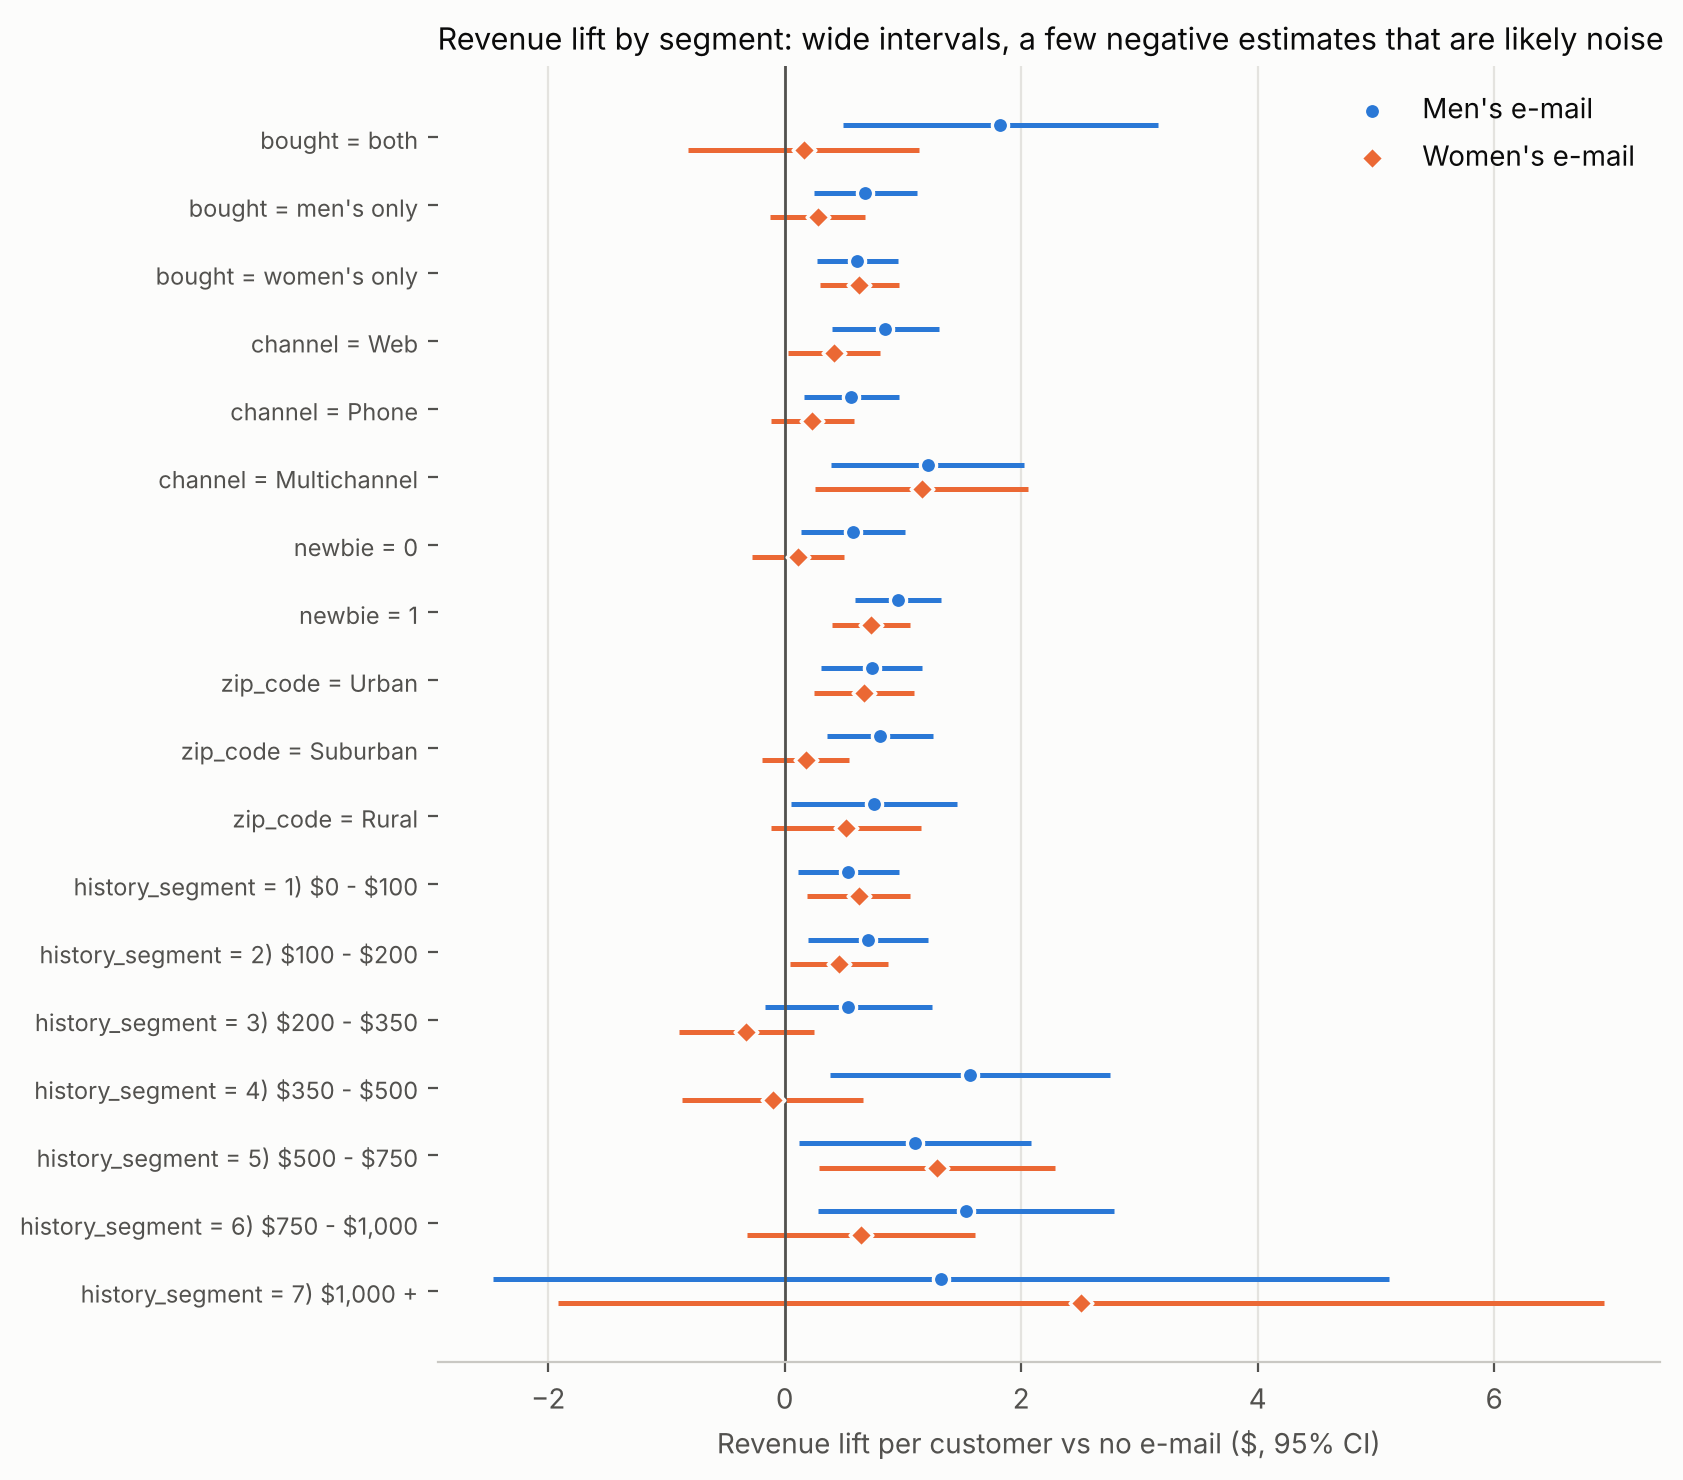

In [3]:
# figure: segments
labels = [s.replace("$", r"\$") for s in seg.loc[seg["email"] == "mens", "segment"]][::-1]
y = np.arange(len(labels))
fig, ax = new_figure(8.5, 7.5)
for offset, email, marker in [(0.18, "mens", "o"), (-0.18, "womens", "D")]:
    s = seg[seg["email"] == email].iloc[::-1]
    ax.hlines(y + offset, s["low"], s["high"], color=ARM_COLORS[email], linewidth=1.8)
    ax.scatter(s["lift"], y + offset, color=ARM_COLORS[email], marker=marker, s=34, zorder=3,
               edgecolor="#fcfcfb", linewidth=1.2, label=ARM_LABELS[email])
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(y, labels, fontsize=8.5, color=INK_2)
style_axes(ax, title="Revenue lift by segment: wide intervals, a few negative estimates that are likely noise",
           xlabel="Revenue lift per customer vs no e-mail ($, 95% CI)", grid="x")
ax.spines["left"].set_visible(False)
ax.legend(frameon=False, loc="upper right", labelcolor=INK)
plt.tight_layout()
plt.show()

Most raw p-values are small, which is no surprise: both emails work for almost everyone. The trap is in the **differences between segments**. The women's email shows *negative* estimates in the \$200–\$500 history segments and its largest estimate in the \$1,000+ segment, with intervals so wide they could hold almost anything. A careless analyst would write "the women's email hurts mid-value customers and works best for top customers". But with 36 comparisons, some extreme-looking results are expected by chance; nothing about mid-value customers suggests an email should *reduce* their spending; and the top segment has only about 1,300 customers in total. After the Holm adjustment, the comparisons that remain significant are the large segments where the overall effect is strongest.

**Rule:** a segment result found by slicing is a hypothesis for the next test, not a finding.

## 2. A hypothesis with a reason: merchandise match

A better approach starts from a business reason. The emails feature men's or women's merchandise, and we know what each customer bought last year. It is plausible that an email works better when its merchandise matches what the customer buys. That gives one specific question instead of 36.

In [4]:
rows = []
for group, g in df.groupby("bought"):
    ctrl = g[g["arm"] == "control"]
    for email in ["mens", "womens"]:
        t = g[g["arm"] == email]
        v = compare_proportions(t["visit"].sum(), len(t), ctrl["visit"].sum(), len(ctrl))
        s = compare_means(t["spend"], ctrl["spend"])
        rows.append({"bought last year": group, "email": ARM_LABELS[email], "customers in group": len(g),
                     "visit lift": v.diff, "visit lift low": v.diff_low, "visit lift high": v.diff_high,
                     "revenue lift": s.diff, "revenue low": s.diff_low, "revenue high": s.diff_high})
match = pd.DataFrame(rows).set_index(["bought last year", "email"])
match.style.format({"customers in group": "{:,}", "visit lift": "{:+.1%}", "visit lift low": "{:+.1%}",
                    "visit lift high": "{:+.1%}", "revenue lift": "${:+.2f}", "revenue low": "${:+.2f}", "revenue high": "${:+.2f}"})

The pattern is clear on visits, the metric with enough data to see it:

- **The men's email lifts visits by about 7 points in every group**, including customers who only buy women's merchandise.
- **The women's email lifts visits by about 7 points among women's buyers, but only about 1 point among customers who only buy men's merchandise.**

Is that difference in the women's email's effect real? Test the interaction directly:

In [5]:
def visit_lift(group, email):
    g = df[df["bought"] == group]
    t, c = g[g["arm"] == email], g[g["arm"] == "control"]
    return compare_proportions(t["visit"].sum(), len(t), c["visit"].sum(), len(c))

a, b = visit_lift("women's only", "womens"), visit_lift("men's only", "womens")
se = np.sqrt(((a.diff_high - a.diff_low) / 3.92) ** 2 + ((b.diff_high - b.diff_low) / 3.92) ** 2)
diff = a.diff - b.diff
print(f"Women's email visit lift, women's-only minus men's-only buyers: {diff:+.1%} "
      f"(95% CI {diff - 1.96 * se:+.1%} to {diff + 1.96 * se:+.1%})")

Women's email visit lift, women's-only minus men's-only buyers: +6.3% (95% CI +5.0% to +7.6%)


A difference of about 6 points, far outside chance. The merchandise-match effect is real for the women's email. For revenue the same pattern appears but with intervals too wide to separate the groups.

**What this means for targeting:** among women's-only buyers, the two emails perform about the same (visit lift 7.1 vs 7.4 points; revenue lift \$0.62 vs \$0.63). Everywhere else the men's email is better. So a "matched" policy (women's email to women's-only buyers, men's email to everyone else) cannot be expected to beat "men's email to everyone" by much. Section 4 checks.

## 3. Uplift models

An **uplift model** predicts, for each customer, how much the email changes their outcome. Two standard approaches:

- **T-learner:** fit one outcome model on emailed customers and one on the holdout; the uplift is the difference of the predictions.
- **S-learner:** fit one model with "was emailed" as a feature; the uplift is the prediction with the flag on minus off.

I train on 70% of customers and evaluate on the other 30% with a **Qini curve**: rank the held-out customers by predicted uplift and plot the incremental outcome gained as we target more of them. A useful model rises steeply at first, above the straight line a random ranking would give.

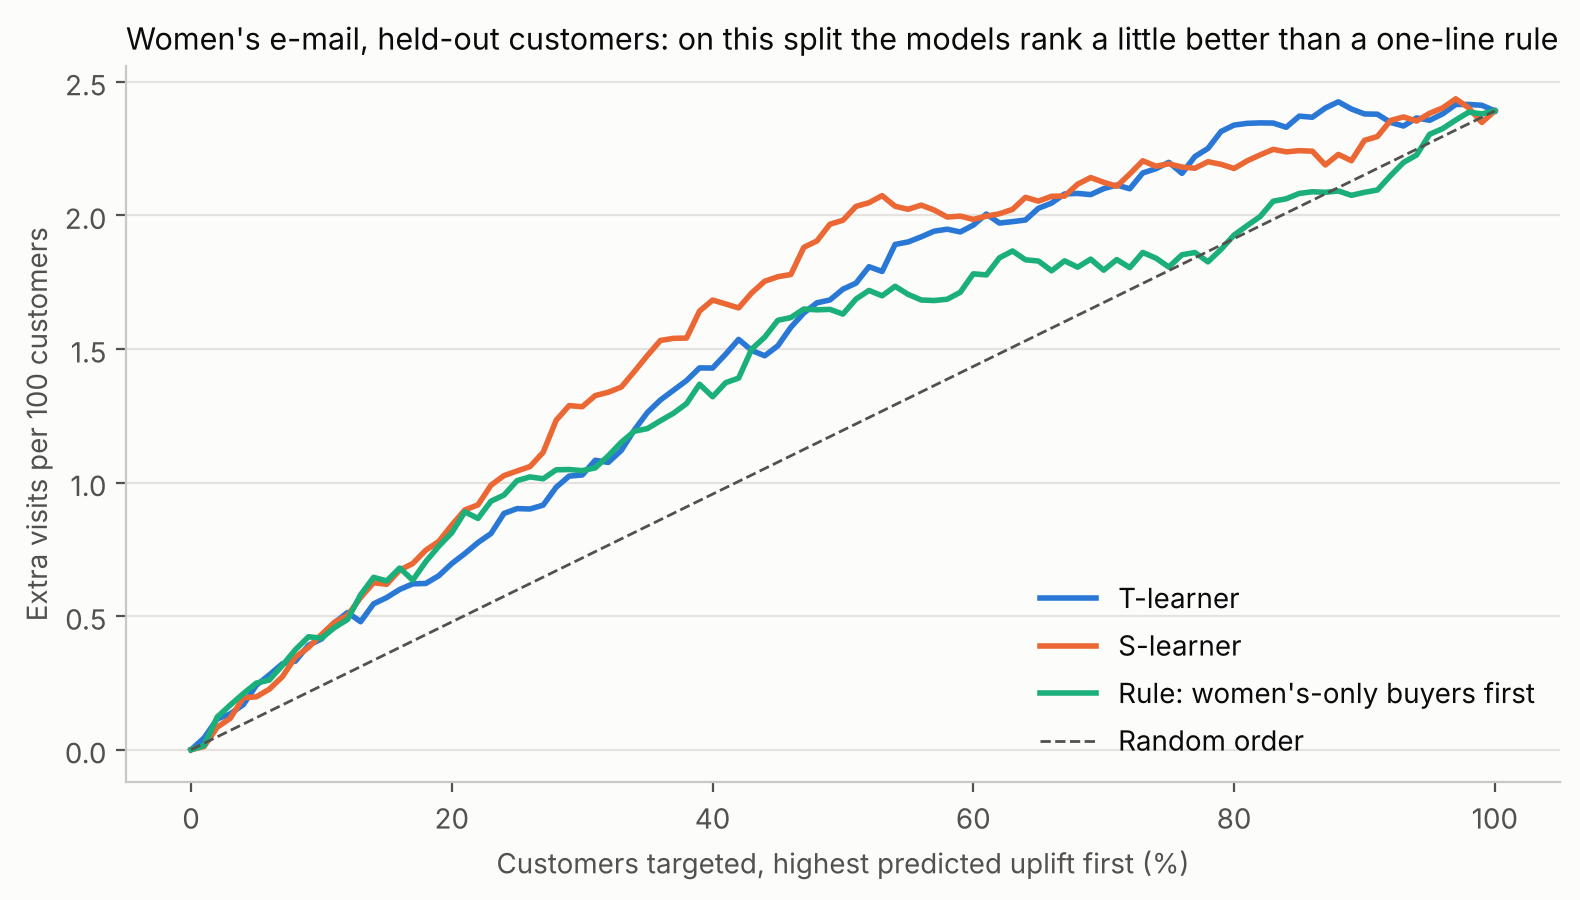

                       T-learner: Qini coefficient 0.0034
                       S-learner: Qini coefficient 0.0041
 Rule: women's-only buyers first: Qini coefficient 0.0023


In [6]:
# figure: qini
X = pd.get_dummies(df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]],
                   columns=["zip_code", "channel"], dtype=float)
make_model = lambda: lgb.LGBMRegressor(n_estimators=200, learning_rate=0.03, num_leaves=8,
                                       min_child_samples=200, verbose=-1)
womens_only = ((df["womens"] == 1) & (df["mens"] == 0)).to_numpy().astype(float)

test = np.random.default_rng(2008).random(len(df)) < 0.3
email = "womens"
train_rows = (~test) & np.isin(arm, ["control", email])
test_rows = test & np.isin(arm, ["control", email])
treated_train = (arm[train_rows] == email).astype(int)
treated_test = (arm[test_rows] == email).astype(int)

scores = {
    "T-learner": t_learner(X[train_rows], df.loc[train_rows, "visit"].to_numpy(), treated_train, X[test_rows], make_model),
    "S-learner": s_learner(X[train_rows], df.loc[train_rows, "visit"].to_numpy(), treated_train, X[test_rows], make_model),
    "Rule: women's-only buyers first": womens_only[test_rows],
}
y_test = df.loc[test_rows, "visit"].to_numpy()

fig, ax = new_figure(8, 4.6)
for (name, s), color in zip(scores.items(), SERIES):
    curve = qini_curve(y_test, treated_test, s)
    ax.plot(curve["fraction"] * 100, curve["gain"] * 100, color=color, linewidth=2, label=name)
ax.plot(curve["fraction"] * 100, curve["random"] * 100, color=INK_2, linewidth=1, linestyle="--", label="Random order")
style_axes(ax, title="Women's e-mail, held-out customers: on this split the models rank a little better than a one-line rule",
           xlabel="Customers targeted, highest predicted uplift first (%)", ylabel="Extra visits per 100 customers")
ax.legend(frameon=False, loc="lower right", labelcolor=INK)
plt.tight_layout()
plt.show()

for name, s in scores.items():
    print(f"{name:>32}: Qini coefficient {qini_coefficient(y_test, treated_test, s):.4f}")

For visits, the models work, and on this split they rank customers somewhat better than a one-line rule. Is that stable, and what about the outcomes that matter for money, purchases and revenue, where there are only a few hundred buyers? One split can be lucky or unlucky, so repeat the whole train/evaluate cycle on 10 different random splits:

In [7]:
rows = []
for seed in range(10):
    split = np.random.default_rng(seed).random(len(df)) < 0.3
    tr = (~split) & np.isin(arm, ["control", email])
    te = split & np.isin(arm, ["control", email])
    t_te = (arm[te] == email).astype(int)
    for outcome in ["visit", "conversion", "spend"]:
        pred = t_learner(X[tr], df.loc[tr, outcome].to_numpy(), (arm[tr] == email).astype(int), X[te], make_model)
        y_te = df.loc[te, outcome].to_numpy()
        rows.append({"outcome": outcome, "T-learner": qini_coefficient(y_te, t_te, pred),
                     "rule": qini_coefficient(y_te, t_te, womens_only[te])})
stability = pd.DataFrame(rows).groupby("outcome")[["T-learner", "rule"]].agg(["mean", "min", "max"])
stability.round(4)

T-learner                    rule                
                mean     min     max    mean     min     max
outcome                                                     
conversion    0.0002  0.0000  0.0004  0.0001 -0.0002  0.0003
spend         0.0196 -0.0524  0.0877  0.0145 -0.0166  0.0581
visit         0.0034  0.0018  0.0043  0.0031  0.0015  0.0044

- **Visits:** the model is slightly better than the rule on average, and both are consistently better than random.
- **Revenue:** the model's Qini swings from clearly *worse* than random on some splits to clearly better on others. With only a few hundred buyers, the model partly learns noise, and whether that helps or hurts depends on which customers happen to land in the test set.

A model whose value depends on the luck of the split is not ready to decide who gets an email. The rule is nearly as good on average, far more stable, easy to explain, and has a business reason behind it.

## 4. Which targeting policy makes the most money?

A **policy** assigns each customer an email (or none). Because assignment was random, we can estimate what any policy would have earned without running it: look at the held-out customers whose random assignment happens to match what the policy would choose, weighted by the chance of that assignment (**inverse propensity weighting**).

The value measured is **net margin per customer**: 40% of revenue, minus $0.0225 for each email sent.

In [8]:
n_test = test.sum()
net_margin = (GROSS_MARGIN * df["spend"] - COST_PER_EMAIL * (df["arm"] != "control")).to_numpy()

pred_test = {}
for e in ["mens", "womens"]:
    tr = (~test) & np.isin(arm, ["control", e])
    for outcome in ["visit", "spend"]:
        pred_test[(outcome, e)] = t_learner(X[tr], df.loc[tr, outcome].to_numpy(), (arm[tr] == e).astype(int), X[test], make_model)

best_revenue = np.maximum(pred_test[("spend", "mens")], pred_test[("spend", "womens")])
policies = {
    "No e-mail": np.full(n_test, "control"),
    "Men's e-mail to all": np.full(n_test, "mens"),
    "Women's e-mail to all": np.full(n_test, "womens"),
    "Match rule": np.where(womens_only[test] == 1, "womens", "mens"),
    "Model (visits)": np.where(pred_test[("visit", "womens")] > pred_test[("visit", "mens")], "womens", "mens"),
    "Model (revenue)": np.where(best_revenue * GROSS_MARGIN < COST_PER_EMAIL, "control",
                                np.where(pred_test[("spend", "womens")] > pred_test[("spend", "mens")], "womens", "mens")),
}
for name, p in policies.items():
    shares = pd.Series(p).value_counts(normalize=True)
    print(f"{name:>22}: " + ", ".join(f"{ARM_LABELS[a]} {s:.0%}" for a, s in shares.items()))

             No e-mail: No e-mail 100%
   Men's e-mail to all: Men's e-mail 100%
 Women's e-mail to all: Women's e-mail 100%
            Match rule: Men's e-mail 55%, Women's e-mail 45%
        Model (visits): Men's e-mail 73%, Women's e-mail 27%
       Model (revenue): Men's e-mail 48%, Women's e-mail 36%, No e-mail 16%


In [9]:
results = compare_policies(net_margin[test], arm[test], policies, {"control": 1 / 3, "mens": 1 / 3, "womens": 1 / 3},
                           baseline="Men's e-mail to all", n_boot=500, seed=1)
results.style.format("${:+.3f}")

,value,value_low,value_high,diff_vs_Men's e-mail to all,diff_low,diff_high
policy,,,,,,
No e-mail,$+0.190,$+0.106,$+0.283,$-0.387,$-0.604,$-0.196
Men's e-mail to all,$+0.577,$+0.405,$+0.761,$+0.000,$+0.000,$+0.000
Women's e-mail to all,$+0.369,$+0.253,$+0.498,$-0.208,$-0.430,$-0.003
Match rule,$+0.551,$+0.399,$+0.720,$-0.026,$-0.158,$+0.111
Model (visits),$+0.485,$+0.345,$+0.649,$-0.092,$-0.236,$+0.035
Model (revenue),$+0.445,$+0.320,$+0.585,$-0.132,$-0.295,$+0.031


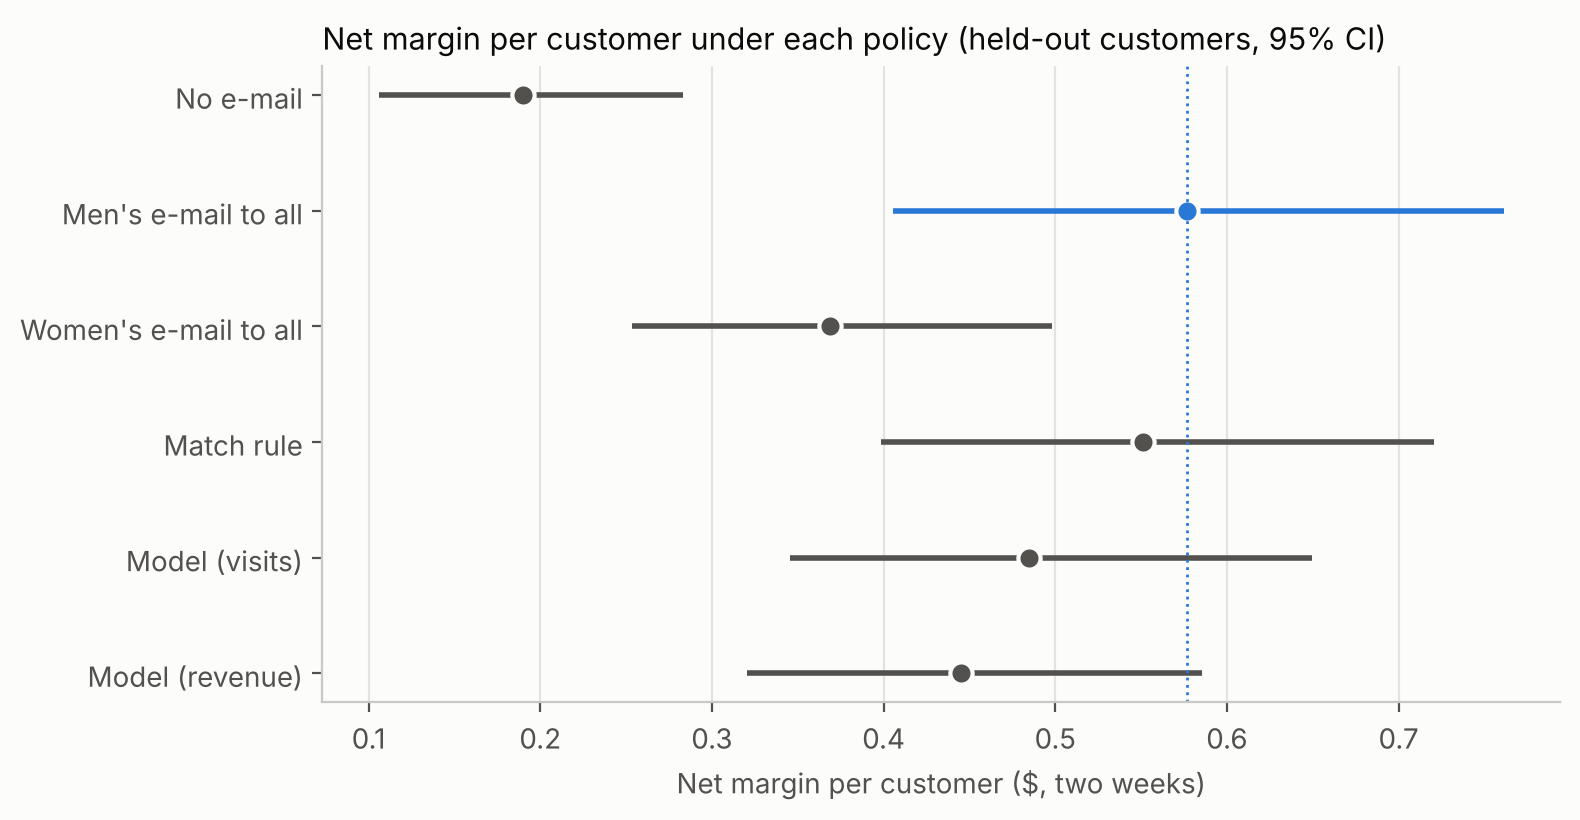

In [10]:
# figure: policies
fig, ax = new_figure(8, 4.2)
names = list(results.index)[::-1]
for i, name in enumerate(names):
    r = results.loc[name]
    color = SERIES[0] if name == "Men's e-mail to all" else INK_2
    ax.hlines(i, r["value_low"], r["value_high"], color=color, linewidth=2)
    ax.plot(r["value"], i, "o", color=color, markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
ax.axvline(results.loc["Men's e-mail to all", "value"], color=SERIES[0], linewidth=1, linestyle=":")
ax.set_yticks(range(len(names)), names)
style_axes(ax, title="Net margin per customer under each policy (held-out customers, 95% CI)",
           xlabel="Net margin per customer ($, two weeks)", grid="x")
plt.tight_layout()
plt.show()

**Sending the men's email to everyone is as good as any targeting policy I tried.** The match rule is statistically tied with it. Both model-based policies come out *lower* (though their intervals overlap with it): the revenue model even withholds email from some customers whose predicted uplift falls below break-even, and loses money doing so, because the email helps nearly everyone.

The held-out set is only 30% of customers, so the match rule is also evaluated on the full data (it needs no training):

In [11]:
full = compare_policies(
    net_margin, arm,
    {"No e-mail": np.full(len(df), "control"), "Men's e-mail to all": np.full(len(df), "mens"),
     "Match rule": np.where(womens_only == 1, "womens", "mens")},
    {"control": 1 / 3, "mens": 1 / 3, "womens": 1 / 3}, baseline="Men's e-mail to all", n_boot=500, seed=1,
)
full.style.format("${:+.3f}")

,value,value_low,value_high,diff_vs_Men's e-mail to all,diff_low,diff_high
policy,,,,,,
No e-mail,$+0.261,$+0.209,$+0.326,$-0.285,$-0.395,$-0.173
Men's e-mail to all,$+0.547,$+0.456,$+0.637,$+0.000,$+0.000,$+0.000
Match rule,$+0.549,$+0.456,$+0.640,$+0.002,$-0.077,$+0.074


Identical to within a fraction of a cent.

## 5. Conclusions

1. **Nobody should be left out.** The men's email lifts visits in every segment, and at a cost of about two cents per email, excluding anyone loses money.
2. **The women's email only works for women's buyers**, a real and explainable pattern, but for those customers it is merely *as good as* the men's email, not better.
3. **Targeting does not beat "men's email to everyone"** on this data. The match rule ties; machine-learning uplift models rank visits only slightly better than the rule, are unstable for revenue, and their policies earned less than men's-to-all on held-out customers.
4. **Recommendation:** send the men's email to the full active file. Keep the merchandise-match idea as a hypothesis for creative development (for example a women's email designed to also appeal to men's buyers), not as a targeting rule.

This is a common and valuable result: before investing in a targeting model, check whether it beats the simple policy of sending the best treatment to everyone.